# 05 · Hindmarsh–Rose: slow adaptation and bursting
## Goal
Extend the single-neuron research sequence from theta/QIF, Hopf, and FitzHugh–Nagumo to a three-state slow–fast model. Establish rest, regular spiking, repeated multi-spike groups, slow modulation, and numerical reliability before coupling neurons.

**Questions:** How do the full equilibrium and frozen-fast dynamics differ? What separates spike frequency from burst frequency? How sensitive are burst counts to the event/grouping definitions? Does changing the slow rate simply stretch time? What numerical evidence is needed before interpreting irregular activity?

**Scope:** deterministic, dimensionless, one neuron; no fitted physiology, physical firing rates, noise, resets, coupling, or network claims. Hindmarsh–Rose (HR) is phenomenological, not a single universal bifurcation normal form. An irregular trace, large ISI coefficient of variation, or scattered return map is **not a verified chaos diagnosis**.

All computations are self-contained; figures, tables, and a JSON summary are saved under `results/hr/` relative to the execution directory. No external data or internet connection are needed to rerun the notebook.

## Setup
### Equations and conventions
Use the catalog's convention:
$$\dot x=y-ax^3+bx^2-z+I,\qquad
\dot y=c-dx^2-y,\qquad
\dot z=r[s(x-x_R)-z],$$
$$a=1,\ b=3,\ c=1,\ d=5,\ s=4,\ x_R=-1.6,\ r=0.006.$$
$x$ is activation/voltage-like, $y$ fast recovery-like, and $z$ slow adaptation-like. Increasing $z$ suppresses $\dot x$ through the $-z$ term; the coupling is a feedback loop, not an independently prescribed forcing waveform. $1/r$ sets a slow relaxation timescale when $x$ is fixed, not a universal burst period.

All states, input, and time are dimensionless. Frequencies are inverse model time, **not Hz**. $I$ and $x_R$ are mathematical parameters, not calibrated current or resting voltage. Published HR variants use different signs/scalings/parameters: their regime boundaries are not transferred to these experiments.

The original [Hindmarsh & Rose (1984) paper](https://pubmed.ncbi.nlm.nih.gov/6144106/) introduces the three-equation bursting model. [Barrio & Shilnikov (2011)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3365907/) studies this equation family using temporal metrics, slow–fast dissection, and Lyapunov methods. Our numerical parameters and experiments are explicitly specified here; they are not a reproduction of that paper's parameter cuts.

### Numerical and measurement choices
- DOP853 default: `rtol=1e-9`, `atol=1e-11`, maximum step 0.5. Radau provides an independent reference for regular regimes.
- Main runs start at $(x,y,z)=(-1.6,-12,3)$, last to $t=6000$, and discard $t<2000$. One initial condition per current is used; no exhaustive basin or bifurcation claims.
- A positive $x=0$ crossing is an operational spike. Spike times use solver event interpolation, not a plotting sample grid. There is no reset.
- Consecutive spikes are grouped when their ISI is at most a selected gap threshold; the default is **50 model-time units**. This is an analysis rule, not a biological constant. Thresholds 30 and 80 are also tested.
- Complete groups require both neighboring separating gaps to lie in the analysis window. Edge groups are censored; no partial group is treated as a complete burst.
- We reserve **multi-spike group** for groups with at least two spikes. A regularly repeating one-spike group is not automatically called a burst. Absence of separated groups is not absence of spiking.
- Deterministic computations; no statistical confidence intervals or randomness. Long-window irregular dynamics are summarized descriptively rather than matched pointwise across solvers.

Choose a Python kernel with NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter. Versions are recorded below; no installation occurs.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OUTPUT_DIR = Path('results')/'hr'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
A, B, C, D, S, X_REF, R = 1., 3., 1., 5., 4., -1.6, 0.006
INITIAL = np.array([-1.6, -12., 3.])
BURN, STOP, GAP = 2000., 6000., 50.
COLORS = {'x': '#2166AC', 'z': '#C56A18', 'neutral': '#444444'}
plt.rcParams.update({'figure.figsize': (9.4, 4.3), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR/f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def hr_rhs(t, state, current, slow_rate=R):
    x, y, z = state
    return np.array([y-A*x**3+B*x*x-z+current, C-D*x*x-y,
                     slow_rate*(S*(x-X_REF)-z)])

def hr_jacobian(state, slow_rate=R):
    x = state[0]
    return np.array([[-3*A*x*x+2*B*x, 1., -1.],
                     [-2*D*x, -1., 0.], [slow_rate*S, 0., -slow_rate]])

def spike_event(t, state):
    return state[0]
spike_event.direction = 1
spike_event.terminal = False

def integrate(current, initial, duration, *, slow_rate=R, method='DOP853',
              rtol=1e-9, atol=1e-11, max_step=0.5):
    options = {}
    if method in ('Radau', 'BDF'):
        options['jac'] = lambda t, state: hr_jacobian(state, slow_rate)
    sol = solve_ivp(lambda t, state: hr_rhs(t, state, current, slow_rate),
                    (0., duration), initial, method=method, rtol=rtol,
                    atol=atol, max_step=max_step, dense_output=True,
                    events=spike_event, **options)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def equilibrium(current):
    # For these coefficients: x³ + 2x² + 4x + 5.4 − I = 0.
    x = brentq(lambda value: A*value**3+(D-B)*value**2+S*value
               -(C+S*X_REF+current), -10, 10, xtol=1e-14, rtol=1e-14)
    return np.array([x, C-D*x*x, S*(x-X_REF)])

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## Steps
### 1. Full-system equilibrium and local stability
At equilibrium,
$$y_*=c-dx_*^2,\quad z_*=s(x_*-x_R),\quad
ax_*^3+(d-b)x_*^2+sx_*-(c+sx_R+I)=0.$$
For our coefficients this polynomial is $x_*^3+2x_*^2+4x_*+5.4-I$. Its derivative is
$$3x_*^2+4x_*+4=3(x_*+2/3)^2+8/3>0,$$
so there is exactly one full-system equilibrium for every current. The Jacobian is
$$J=\begin{pmatrix}
-3ax_*^2+2bx_*&1&-1\\
-2dx_*&-1&0\\
rs&0&-r
\end{pmatrix}.$$
All eigenvalues must have negative real part for linear asymptotic stability. A positive real part establishes local instability, not a unique attractor or a specific bursting mechanism. The plot below is an equilibrium calculation, not a bifurcation diagram of periodic orbits. We do not compute Hopf criticality or unstable cycles here.

,I,x_eq,y_eq,z_eq,max_real_eigenvalue
0,0.0000000,-1.6045345,-11.8726553,-0.0181381,-0.0393316
100,1.3333333,-1.3127534,-7.6166071,1.1489865,-0.0009094
150,2.0000000,-1.1272491,-5.3534523,1.8910037,0.0260098
225,3.0000000,-0.7882155,-2.1064182,3.2471381,0.1427994
300,4.0000000,-0.4195480,0.1198974,4.7218080,0.2401624


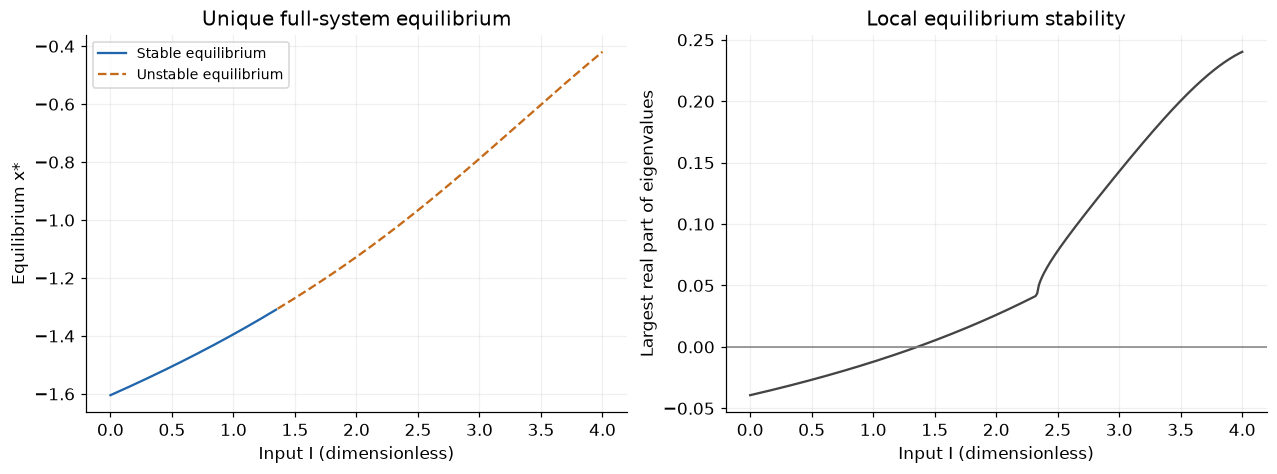

In [3]:
equilibrium_rows = []
for current in np.linspace(0., 4., 301):
    point = equilibrium(current)
    eigenvalues = np.linalg.eigvals(hr_jacobian(point))
    equilibrium_rows.append({'I': current, 'x_eq': point[0], 'y_eq': point[1],
                             'z_eq': point[2],
                             'max_real_eigenvalue': float(eigenvalues.real.max())})
equilibrium_table = pd.DataFrame(equilibrium_rows)
equilibrium_table.to_csv(OUTPUT_DIR/'equilibrium_stability.csv', index=False)
display(equilibrium_table.iloc[[0, 100, 150, 225, 300]])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
stable_mask = equilibrium_table.max_real_eigenvalue < 0
axes[0].plot(equilibrium_table.I, equilibrium_table.x_eq.where(stable_mask),
              color=COLORS['x'], label='Stable equilibrium')
axes[0].plot(equilibrium_table.I, equilibrium_table.x_eq.where(~stable_mask),
              '--', color=COLORS['z'], label='Unstable equilibrium')
axes[1].plot(equilibrium_table.I, equilibrium_table.max_real_eigenvalue,
              color=COLORS['neutral'])
axes[1].axhline(0, color='0.5', linewidth=1)
for ax in axes:
    ax.set_xlabel('Input I (dimensionless)')
axes[0].set(ylabel='Equilibrium x*', title='Unique full-system equilibrium')
axes[0].legend(fontsize=9, loc='upper left')
axes[1].set(ylabel='Largest real part of eigenvalues', title='Local equilibrium stability')
show_and_save(fig, '01_equilibrium_stability')

### 2. Spike and complete-group definitions
For a sorted spike-time sequence $t_k$, an ISI greater than $G$ separates two groups. A complete group has a preceding and following separating interval fully inside the analysis window. This discards groups censored at either edge.

We report:
- spike rate $N_{spikes}/T_{window}$ (a finite-window count rate);
- mean ISI and ISI CV $\operatorname{std}(ISI)/\operatorname{mean}(ISI)$ using population standard deviation;
- spike count per complete group and group-onset intervals;
- group **spike-span** duration $t_{last}-t_{first}$, not the full active-phase duration.

A regular burst has unequal within-burst and between-burst ISIs, so a large ISI CV can occur without irregularity. We do not classify chaos from CV. Group-onset frequency and overall spike rate are different observables.

In [5]:
GROUP_COLUMNS = ['group_onset', 'last_spike', 'n_spikes', 'spike_span',
                 'preceding_isi', 'following_isi']

def complete_groups(spikes, start, stop, gap=GAP):
    spikes = np.asarray(spikes, dtype=float)
    if gap <= 0 or not stop > start:
        raise ValueError('Require positive gap and nonempty window.')
    if len(spikes) < 3:
        return pd.DataFrame(columns=GROUP_COLUMNS)
    groups = np.split(spikes, np.flatnonzero(np.diff(spikes) > gap)+1)
    rows = []
    for k in range(1, len(groups)-1):
        previous, group, following = groups[k-1], groups[k], groups[k+1]
        if previous[-1] >= start and following[0] <= stop:
            rows.append({'group_onset': group[0], 'last_spike': group[-1],
                         'n_spikes': len(group), 'spike_span': group[-1]-group[0],
                         'preceding_isi': group[0]-previous[-1],
                         'following_isi': following[0]-group[-1]})
    return pd.DataFrame(rows, columns=GROUP_COLUMNS)

def metrics(solution, start, stop, gap=GAP):
    spikes = solution.t_events[0]
    selected = spikes[(spikes >= start) & (spikes < stop)]
    intervals = np.diff(selected)
    groups = complete_groups(spikes, start, stop, gap)
    onsets = groups.group_onset.to_numpy(dtype=float)
    group_intervals = np.diff(onsets)
    return {'spikes_in_window': len(selected), 'spike_rate': len(selected)/(stop-start),
            'mean_isi': float(intervals.mean()) if len(intervals) else np.nan,
            'isi_cv': float(intervals.std(ddof=0)/intervals.mean()) if len(intervals) else np.nan,
            'complete_groups': len(groups),
            'mean_spikes_per_group': float(groups.n_spikes.mean()) if len(groups) else np.nan,
            'min_spikes_per_group': int(groups.n_spikes.min()) if len(groups) else np.nan,
            'max_spikes_per_group': int(groups.n_spikes.max()) if len(groups) else np.nan,
            'mean_group_period': float(group_intervals.mean()) if len(group_intervals) else np.nan,
            'group_period_cv': float(group_intervals.std(ddof=0)/group_intervals.mean()) if len(group_intervals) else np.nan}

# Known synthetic event schedule tests censoring and grouping logic only.
# This is not simulated neuronal evidence.
example_events = np.array([0., 1., 10., 11., 20., 21., 30., 31.])
example_groups = complete_groups(example_events, 0., 32., gap=5.)
assert example_groups.group_onset.tolist() == [10., 20.]
assert example_groups.n_spikes.tolist() == [2, 2]
assert len(complete_groups(np.arange(10.), 0, 10, gap=5)) == 0

### 3. Rest, regular bursts, irregular activity, and tonic spiking
Run four currents $I=0,2,3.25,4$. Plot the same post-transient window $4800\leq t\leq5400$. Activation axes have a common range; **slow-variable axes are independently scaled** to reveal their different modulation amplitudes. The resting $z$ axis is given a fixed ±0.1 range around its equilibrium to avoid magnifying roundoff.

Regime descriptions follow the measured trajectories; an illustrative current is not a universal literature boundary. The $I=3.25$ case is descriptive irregular spiking/grouping, with no Lyapunov diagnosis in this notebook.

,I,spikes_in_window,mean_isi,isi_cv,complete_groups,mean_spikes_per_group,mean_group_period
0,0.00,0,NaN,NaN,0,NaN,NaN
1,2.00,62,63.4418338,7.7928471e-01,29,2.000,128.5048446
2,3.25,123,32.4763369,6.7791205e-01,32,3.625,117.4279754
3,4.00,198,20.1278685,1.7536043e-14,0,NaN,NaN


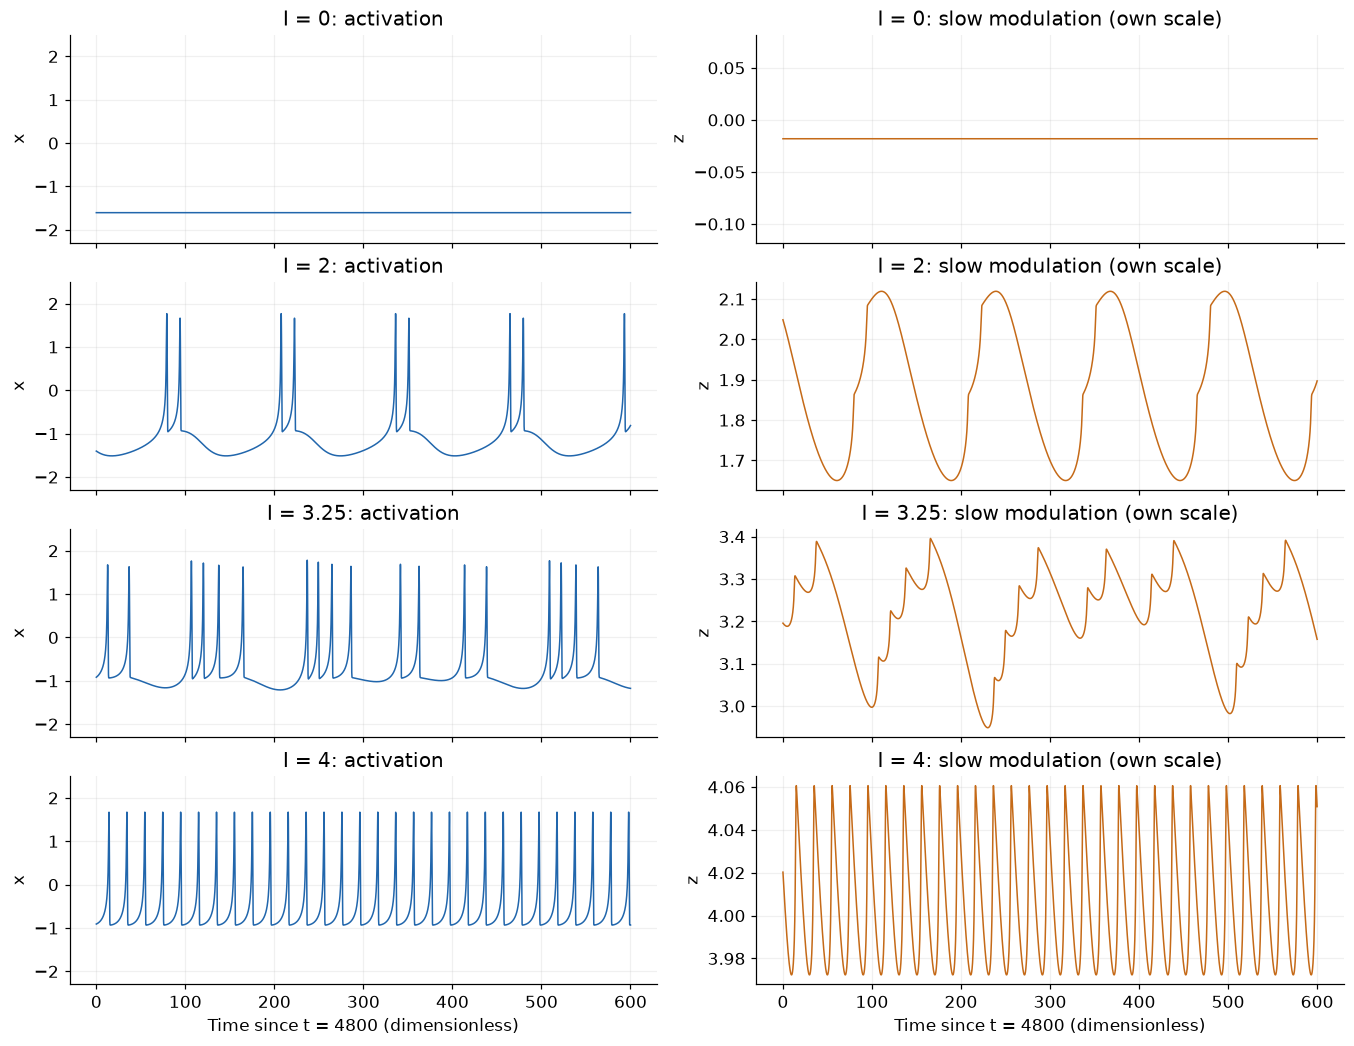

In [7]:
MAIN_CURRENTS = [0., 2., 3.25, 4.]
solutions = {current: integrate(current, INITIAL, STOP) for current in MAIN_CURRENTS}
regime_rows = []
for current, sol in solutions.items():
    regime_rows.append({'I': current, **metrics(sol, BURN, STOP),
                        'final_distance_to_equilibrium': float(np.linalg.norm(sol.y[:, -1]-equilibrium(current)))})
regime_table = pd.DataFrame(regime_rows)
regime_table.to_csv(OUTPUT_DIR/'main_regime_metrics.csv', index=False)
display(regime_table[['I', 'spikes_in_window', 'mean_isi', 'isi_cv',
                       'complete_groups', 'mean_spikes_per_group', 'mean_group_period']])
fig, axes = plt.subplots(4, 2, figsize=(12.2, 9.4), sharex=True, layout='constrained')
plot_times = np.linspace(4800, 5400, 12001)
for row, current in enumerate(MAIN_CURRENTS):
    values = solutions[current].sol(plot_times)
    axes[row, 0].plot(plot_times-4800, values[0], color=COLORS['x'], linewidth=1)
    axes[row, 1].plot(plot_times-4800, values[2], color=COLORS['z'], linewidth=1)
    axes[row, 0].set(title=f'I = {current:g}: activation', ylabel='x', ylim=(-2.3, 2.5))
    axes[row, 1].set(title=f'I = {current:g}: slow modulation (own scale)', ylabel='z')
    axes[row, 1].ticklabel_format(useOffset=False, style='plain', axis='y')
    if current == 0:
        z0 = equilibrium(0)[2]
        axes[row, 1].set_ylim(z0-0.1, z0+0.1)
for ax in axes[-1]:
    ax.set_xlabel('Time since t = 4800 (dimensionless)')
show_and_save(fig, '02_activation_and_adaptation')

### 4. ISI sequences and return maps
A regular two-spike burst alternates a short and a long ISI; its return map can contain two points even though the burst repeats periodically. The tonic case has a nearly single-valued ISI. More dispersed points describe variability but do not by themselves establish deterministic chaos, exclude a long periodic orbit, or quantify a Lyapunov exponent.

Use the first 100 ISIs within the post-transient window for the sequence view, and all post-transient adjacent ISI pairs for the return map. Both coordinates of each return map use common scales. We also compare two nonoverlapping 2000-unit windows descriptively; finite-window differences are not confidence intervals.

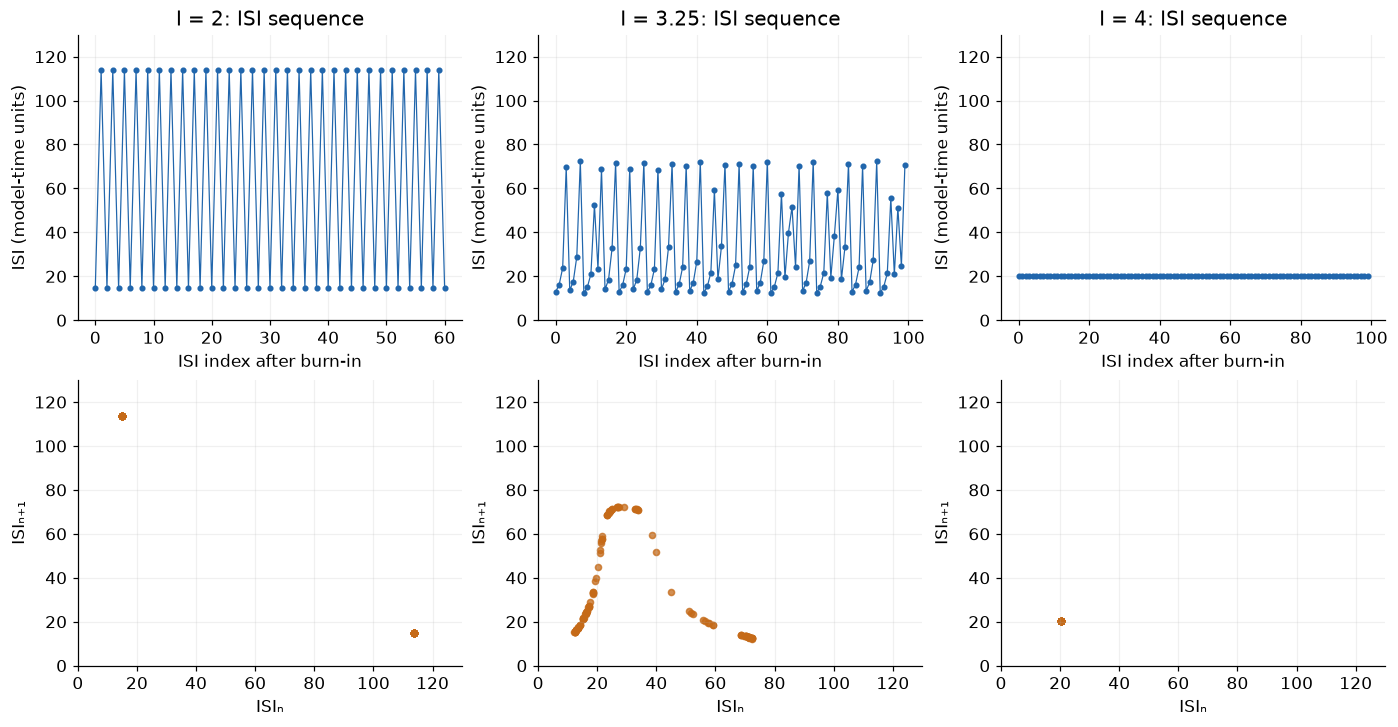

,I,window_start,spikes_in_window,isi_cv,complete_groups,mean_spikes_per_group
0,2.00,2000.0,32,7.8873634e-01,14,2.0000
1,2.00,4000.0,30,7.9006476e-01,13,2.0000
2,3.25,2000.0,62,7.0301156e-01,15,3.8000
3,3.25,4000.0,61,6.4632507e-01,16,3.4375
4,4.00,2000.0,99,1.5173838e-14,0,NaN
5,4.00,4000.0,99,1.9612328e-14,0,NaN


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(12.6, 6.5), layout='constrained')
window_rows = []
for column, current in enumerate([2., 3.25, 4.]):
    all_spikes = solutions[current].t_events[0]
    spikes = all_spikes[(all_spikes >= BURN) & (all_spikes < STOP)]
    intervals = np.diff(spikes)
    axes[0, column].plot(np.arange(min(100, len(intervals))), intervals[:100],
                         'o-', markersize=3, color=COLORS['x'], linewidth=0.8)
    axes[0, column].set(title=f'I = {current:g}: ISI sequence', xlabel='ISI index after burn-in',
                        ylabel='ISI (model-time units)', ylim=(0, 130))
    axes[1, column].scatter(intervals[:-1], intervals[1:], s=16, color=COLORS['z'], alpha=0.75)
    axes[1, column].set(xlabel='ISIₙ', ylabel='ISIₙ₊₁', xlim=(0, 130), ylim=(0, 130))
    for start, stop in [(2000., 4000.), (4000., 6000.)]:
        window_rows.append({'I': current, 'window_start': start, 'window_stop': stop,
                            **metrics(solutions[current], start, stop)})
show_and_save(fig, '03_isi_sequences_and_return_maps')
window_table = pd.DataFrame(window_rows)
window_table.to_csv(OUTPUT_DIR/'window_sensitivity.csv', index=False)
display(window_table[['I', 'window_start', 'spikes_in_window', 'isi_cv',
                       'complete_groups', 'mean_spikes_per_group']])

### 5. Frozen-fast dissection: equilibrium branches versus the full orbit
Freeze $z$ and study only $(x,y)$. Its equilibrium curve is
$$y=c-dx^2,\qquad z=I+c+(b-d)x^2-ax^3,$$
with fast Jacobian
$$J_f=\begin{pmatrix}-3ax^2+2bx&1\\-2dx&-1\end{pmatrix}.$$
For these coefficients $\det J_f=3x^2+4x$ and $\operatorname{tr}J_f=-3x^2+6x-1$. The fast equilibrium folds are at $x=-4/3$ and $x=0$, with $z=I-5/27$ and $z=I+1$. These are **fast-subsystem** folds, not folds of the unique full-system equilibrium.

For $I=2$, overlay the full bursting orbit on the frozen-fast branch diagram. We additionally simulate selected frozen-$z$ systems from $(x,y)=(1,0)$ for 700 time units; cycle envelopes are displayed only when recent spike periods and section states meet simple stationarity checks. Missing envelopes are not proof of absence of a fast cycle or of its bifurcation location. A slow nullcline $x=z/s+x_R$ is also shown; slow motion depends on the averaged fast trajectory, not only on equilibrium intersections.

This dissection explains a candidate geometric organization. Without periodic-orbit continuation and a homoclinic calculation, we do not claim to identify exact burst-onset/termination bifurcations solely from the waveform.

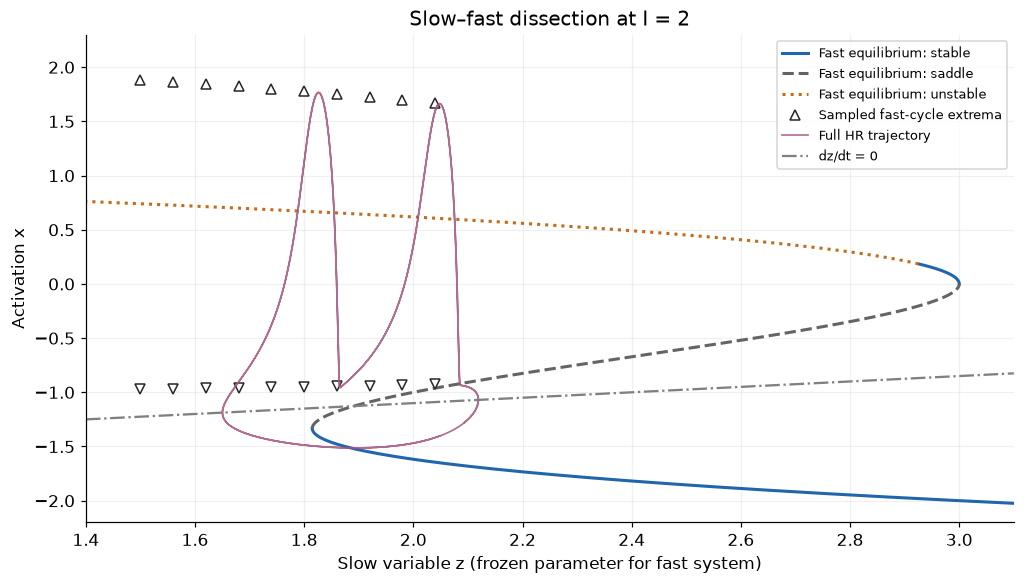

In [11]:
def fast_rhs(t, state, current, frozen_z):
    x, y = state
    return np.array([y-A*x**3+B*x*x-frozen_z+current, C-D*x*x-y])

def fast_jacobian(x):
    return np.array([[-3*A*x*x+2*B*x, 1.], [-2*D*x, -1.]])

def integrate_fast(current, frozen_z, initial, duration, *, rtol=1e-9, atol=1e-11, max_step=0.5):
    sol = solve_ivp(lambda t, state: fast_rhs(t, state, current, frozen_z),
                    (0, duration), initial, method='DOP853', rtol=rtol,
                    atol=atol, max_step=max_step, dense_output=True, events=spike_event)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

FAST_CURRENT = 2.
fast_rows = []
for frozen_z in np.r_[np.linspace(1.5, 2.4, 16), 2.6, 2.8]:
    sol = integrate_fast(FAST_CURRENT, frozen_z, [1., 0.], 700.)
    events = sol.t_events[0]
    recent_indices = np.flatnonzero(events > 350)
    outcome, vmin, vmax, period = 'unresolved/nonspiking', np.nan, np.nan, np.nan
    if len(recent_indices) >= 4:
        chosen = recent_indices[-4:]
        intervals = np.diff(events[chosen])
        closure = np.max(np.linalg.norm(np.diff(sol.y_events[0][chosen], axis=0), axis=1))
        if intervals.std(ddof=0)/intervals.mean() < 1e-5 and closure < 1e-6:
            period = float(intervals.mean())
            vv = sol.sol(np.linspace(events[chosen[-2]], events[chosen[-1]], 2001))[0]
            vmin, vmax = float(vv.min()), float(vv.max())
            outcome = 'settled fast cycle'
    fast_rows.append({'z': frozen_z, 'outcome': outcome, 'sampled_x_min': vmin,
                      'sampled_x_max': vmax, 'period': period})
fast_table = pd.DataFrame(fast_rows)
fast_table.to_csv(OUTPUT_DIR/'frozen_fast_cycles.csv', index=False)
xx = np.linspace(-2.2, 2.3, 2001)
zz = FAST_CURRENT+C+(B-D)*xx**2-A*xx**3
classification = []
for value in xx:
    eig = np.linalg.eigvals(fast_jacobian(value))
    if np.linalg.det(fast_jacobian(value)) < 0:
        classification.append('saddle')
    elif eig.real.max() < 0:
        classification.append('stable')
    else:
        classification.append('unstable')
classification = np.array(classification)
fig, ax = plt.subplots(figsize=(9.2, 5.2), layout='constrained')
for label, color, style in [('stable', '#2166AC', '-'), ('saddle', '#646464', '--'),
                             ('unstable', '#C56A18', ':')]:
    ax.plot(zz, np.where(classification == label, xx, np.nan), style,
             color=color, linewidth=2, label=f'Fast equilibrium: {label}')
cycle_mask = fast_table.outcome == 'settled fast cycle'
ax.plot(fast_table.loc[cycle_mask, 'z'], fast_table.loc[cycle_mask, 'sampled_x_max'],
         '^', mfc='white', mec='0.15', label='Sampled fast-cycle extrema')
ax.plot(fast_table.loc[cycle_mask, 'z'], fast_table.loc[cycle_mask, 'sampled_x_min'],
         'v', mfc='white', mec='0.15')
full_values = solutions[2.].sol(np.linspace(4800, 5050, 10001))
ax.plot(full_values[2], full_values[0], color='#A3537B', linewidth=1.1,
         alpha=0.85, label='Full HR trajectory')
zgrid = np.linspace(1.4, 3.1, 300)
ax.plot(zgrid, zgrid/S+X_REF, '-.', color='0.5', label='dz/dt = 0')
ax.set(xlabel='Slow variable z (frozen parameter for fast system)', ylabel='Activation x',
        title='Slow–fast dissection at I = 2', xlim=(1.4, 3.1), ylim=(-2.2, 2.3))
ax.legend(fontsize=8.5, loc='upper right')
show_and_save(fig, '04_frozen_fast_dissection')

### 6. Burst grouping sensitivity
Repeat the complete-group calculation at gaps $G=30,50,80$ for $I=2$ and $I=3.25$. The regular burst is expected to have a clear short/long separation. An irregular trace may lack a single robust separation; at a sufficiently large gap, every spike can be connected into one censored group, leaving no complete groups.

Do not substitute zero for missing mean group size/period when no complete groups exist. The ISI return map and raw waveform remain available independently of any grouping convention.

,I,gap_threshold,complete_groups,mean_spikes_per_group,distinct_complete_group_sizes
0,2.00,30.0,29,2.0000000,2
1,2.00,50.0,29,2.0000000,2
2,2.00,80.0,29,2.0000000,2
3,3.25,30.0,41,2.8292683,"1,2,3,4"
4,3.25,50.0,32,3.6250000,"2,3,4"
5,3.25,80.0,0,NaN,


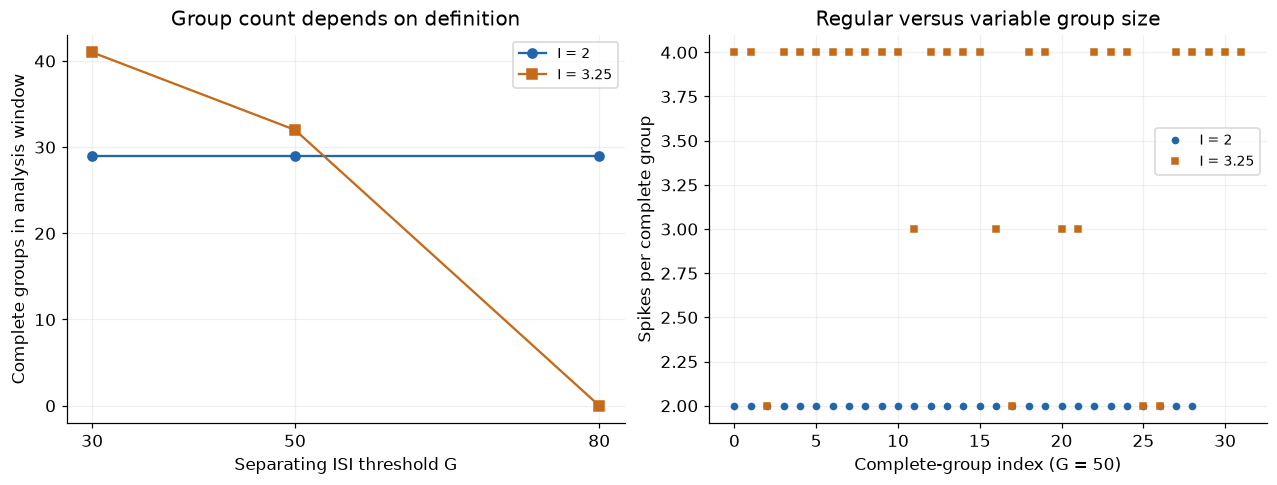

In [13]:
sensitivity_rows = []
for current in [2., 3.25]:
    for gap in [30., 50., 80.]:
        groups = complete_groups(solutions[current].t_events[0], BURN, STOP, gap)
        sensitivity_rows.append({'I': current, 'gap_threshold': gap,
                                  **metrics(solutions[current], BURN, STOP, gap),
                                  'distinct_complete_group_sizes':
                                  ','.join(str(int(n)) for n in sorted(groups.n_spikes.unique()))})
sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.to_csv(OUTPUT_DIR/'grouping_sensitivity.csv', index=False)
display(sensitivity_table[['I', 'gap_threshold', 'complete_groups',
                            'mean_spikes_per_group', 'distinct_complete_group_sizes']])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')
for current, color, marker in [(2., COLORS['x'], 'o'), (3.25, COLORS['z'], 's')]:
    part = sensitivity_table[sensitivity_table.I == current]
    axes[0].plot(part.gap_threshold, part.complete_groups, marker+'-', color=color, label=f'I = {current:g}')
    groups = complete_groups(solutions[current].t_events[0], BURN, STOP, GAP)
    axes[1].plot(np.arange(len(groups)), groups.n_spikes, marker,
                  color=color, markersize=4, label=f'I = {current:g}')
axes[0].set(xlabel='Separating ISI threshold G', ylabel='Complete groups in analysis window',
            title='Group count depends on definition', xticks=[30, 50, 80])
axes[1].set(xlabel='Complete-group index (G = 50)', ylabel='Spikes per complete group',
            title='Regular versus variable group size')
axes[0].legend(fontsize=9, loc='upper right')
axes[1].legend(fontsize=9, loc='center right', bbox_to_anchor=(1, 0.7))
show_and_save(fig, '05_grouping_sensitivity')

### 7. A bounded current scan
Add currents $I=1.3,2.5,3,3.5$ to the four main runs, keeping the same initial condition, burn-in, and analysis interval. Plot all post-transient ISIs and finite-window spike rates. A mean rate alone hides grouping; a large CV alone hides periodic alternating ISIs. No exact transition boundary, multistability survey, or full bifurcation continuation is claimed.

Any run with no observed spikes is labeled by its endpoint distance to equilibrium in the exported metrics; a finite silent window by itself is not proof of asymptotic rest. The slow decay near a stability boundary can demand longer transients than the fixed default.

,I,spike_rate,isi_cv,complete_groups,mean_spikes_per_group,final_distance_to_equilibrium
0,0.00,0.00000,NaN,0,NaN,7.1213642e-10
1,1.30,0.00000,NaN,0,NaN,1.4874851e-05
2,2.00,0.01550,7.7928471e-01,29,2.0000000,3.3836305e+00
3,2.50,0.02425,9.1233844e-01,31,3.0000000,8.9603197e-01
4,3.00,0.02925,8.4006775e-01,31,3.5483871,3.3544484e+00
5,3.25,0.03075,6.7791205e-01,32,3.6250000,1.8841563e+00
6,3.50,0.03150,2.2240080e-03,0,NaN,6.9688785e-01
7,4.00,0.04950,1.7536043e-14,0,NaN,8.1206849e-01


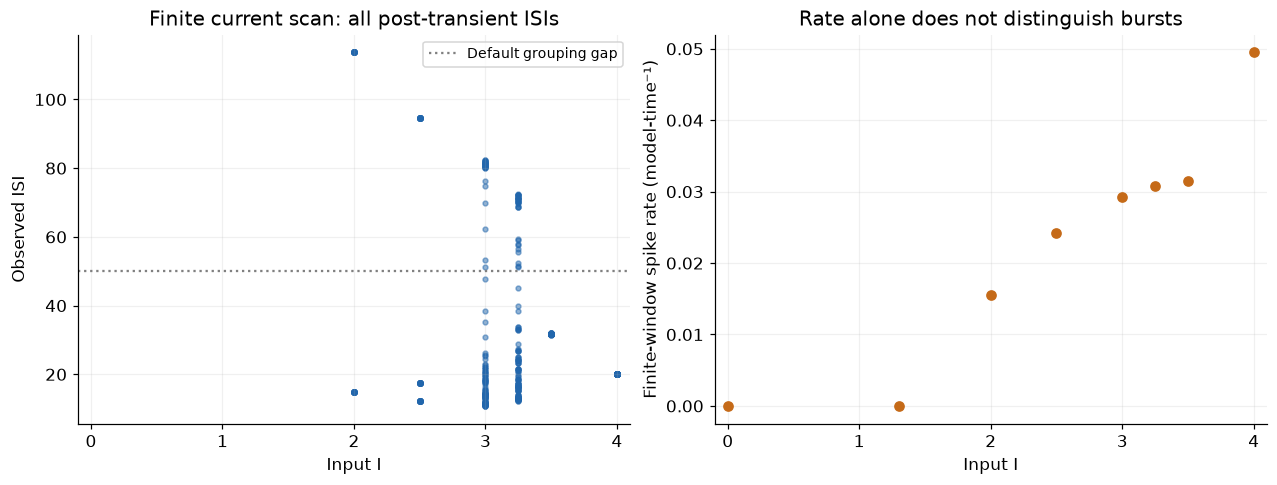

In [15]:
for current in [1.3, 2.5, 3., 3.5]:
    solutions[current] = integrate(current, INITIAL, STOP)
scan_rows = []
for current in sorted(solutions):
    sol = solutions[current]
    scan_rows.append({'I': current, **metrics(sol, BURN, STOP),
                      'final_distance_to_equilibrium': float(np.linalg.norm(sol.y[:, -1]-equilibrium(current)))})
scan_table = pd.DataFrame(scan_rows)
scan_table.to_csv(OUTPUT_DIR/'current_scan.csv', index=False)
event_rows, group_frames = [], []
for current, sol in sorted(solutions.items()):
    for time, state in zip(sol.t_events[0], sol.y_events[0]):
        event_rows.append({'I': current, 'spike_time': time,
                           'y_at_spike': state[1], 'z_at_spike': state[2],
                           'in_analysis_window': bool(BURN <= time < STOP)})
    groups = complete_groups(sol.t_events[0], BURN, STOP)
    if len(groups):
        group_frames.append(groups.assign(I=current, gap_threshold=GAP))
pd.DataFrame(event_rows).to_csv(OUTPUT_DIR/'spike_events.csv', index=False)
if group_frames:
    pd.concat(group_frames, ignore_index=True).to_csv(OUTPUT_DIR/'complete_groups.csv', index=False)

display(scan_table[['I', 'spike_rate', 'isi_cv', 'complete_groups',
                     'mean_spikes_per_group', 'final_distance_to_equilibrium']])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')
for current, sol in sorted(solutions.items()):
    events = sol.t_events[0]
    intervals = np.diff(events[(events >= BURN) & (events < STOP)])
    axes[0].scatter(np.full(len(intervals), current), intervals, s=10,
                     color=COLORS['x'], alpha=0.5)
axes[0].axhline(GAP, color='0.5', linestyle=':', label='Default grouping gap')
axes[0].set(xlabel='Input I', ylabel='Observed ISI', title='Finite current scan: all post-transient ISIs')
axes[0].legend(fontsize=9, loc='upper right')
axes[1].plot(scan_table.I, scan_table.spike_rate, 'o', color=COLORS['z'])
axes[1].set(xlabel='Input I', ylabel='Finite-window spike rate (model-time⁻¹)',
            title='Rate alone does not distinguish bursts')
for ax in axes:
    ax.set_xlim(-0.1, 4.1)
    ax.set_xticks([0, 1, 2, 3, 4])
show_and_save(fig, '06_current_scan')

### 8. Changing the slow rate is not a pure time rescaling
At fixed $I=2$, use $r=0.012,0.006,0.003$. For each value run to $36/r$ and discard $t<12/r$. This gives comparable slow-time horizons; the $r=0.006$ trajectory is reused. All other coefficients and the initial condition are unchanged.

Report complete-group size, group-onset period, and $rT_{group}$. Multiplying the entire ODE by a constant would rescale all times without changing trajectories; changing only the $z$ equation can also change spike counts and waveform geometry. No exact $T\propto1/r$ law or universal burst grouping is assumed. One-spike groups, if present, remain explicitly labeled by count.

,r,mean_spikes_per_group,mean_group_period,scaled_group_period_rT,group_period_cv
0,0.012,1.0,87.4799735,1.0497597,7.3249442e-08
1,0.006,2.0,128.5048446,0.7710291,2.6689582e-11
2,0.003,4.0,204.7638107,0.6142914,5.0715435e-11


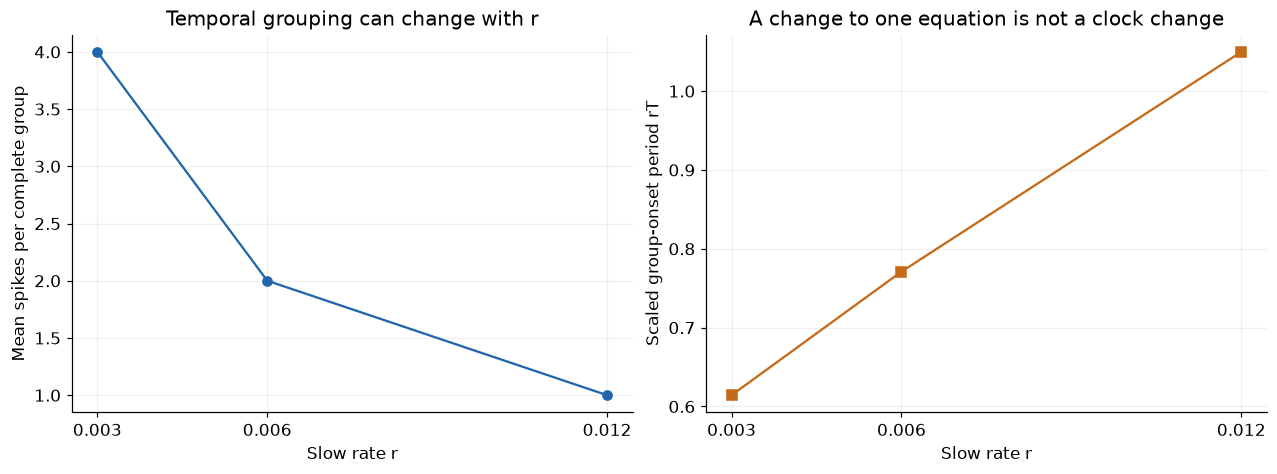

In [17]:
slow_rows = []
for slow_rate in [0.012, 0.006, 0.003]:
    start, stop = 12/slow_rate, 36/slow_rate
    sol = solutions[2.] if slow_rate == R else integrate(2., INITIAL, stop, slow_rate=slow_rate)
    measured = metrics(sol, start, stop)
    slow_rows.append({'r': slow_rate, 'window_start': start, 'window_stop': stop,
                      **measured, 'scaled_group_period_rT': slow_rate*measured['mean_group_period']})
slow_table = pd.DataFrame(slow_rows)
slow_table.to_csv(OUTPUT_DIR/'slow_rate_comparison.csv', index=False)
display(slow_table[['r', 'mean_spikes_per_group', 'mean_group_period',
                     'scaled_group_period_rT', 'group_period_cv']])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].plot(slow_table.r, slow_table.mean_spikes_per_group, 'o-', color=COLORS['x'])
axes[0].set(xlabel='Slow rate r', ylabel='Mean spikes per complete group',
            title='Temporal grouping can change with r')
axes[1].plot(slow_table.r, slow_table.scaled_group_period_rT, 's-', color=COLORS['z'])
axes[1].set(xlabel='Slow rate r', ylabel='Scaled group-onset period rT',
            title='A change to one equation is not a clock change')
for ax in axes:
    ax.set_xticks([0.003, 0.006, 0.012], ['0.003', '0.006', '0.012'])
show_and_save(fig, '07_slow_rate_comparison')

### 9. Numerical convergence in regular regimes
An irregular trajectory can diverge pointwise under tiny numerical perturbations; that alone neither proves chaos nor supplies an accuracy test. We therefore benchmark regular tonic spiking ($I=4$) and the repeating two-spike group ($I=2$).

For tonic spiking, initialize at the final positive $x=0$ section state from the long run and integrate 400 units. Tight Radau (`rtol=1e-11`, `atol=1e-13`, maximum step 0.1) is a **numerical reference**, cross-checked with tight DOP853 at the same step cap. RK45 tolerances $10^{-4},10^{-6},10^{-8},10^{-10}$ test the mean of the last 5 ISIs and the common-grid $x(t)$ discrepancy over the first 200 units. The latter includes phase drift.

For the regular multi-spike case, initialize at a complete-group onset state and compare Radau and DOP853 over 650 units using complete-group onset intervals. Averaging all ISIs would conflate the short intragroup and long intergroup intervals. No exact full HR nonlinear period is claimed.

,rtol,tonic_period,relative_period_error,max_x_trajectory_error,nfev
0,1.0000000e-04,20.1148709,6.4575001e-04,3.1579040e-01,8204
1,1.0000000e-06,20.1278530,7.7062899e-07,4.0670128e-04,14384
2,1.0000000e-08,20.1278684,3.1166590e-09,7.9921204e-07,31916
3,1.0000000e-10,20.1278685,5.3359539e-12,1.2178136e-08,74930


Tonic numerical reference period: 20.127868469
Two-spike-group numerical reference period: 128.504844600
Radau/DOP853 relative differences: tonic 1.112e-12, group 2.844e-12


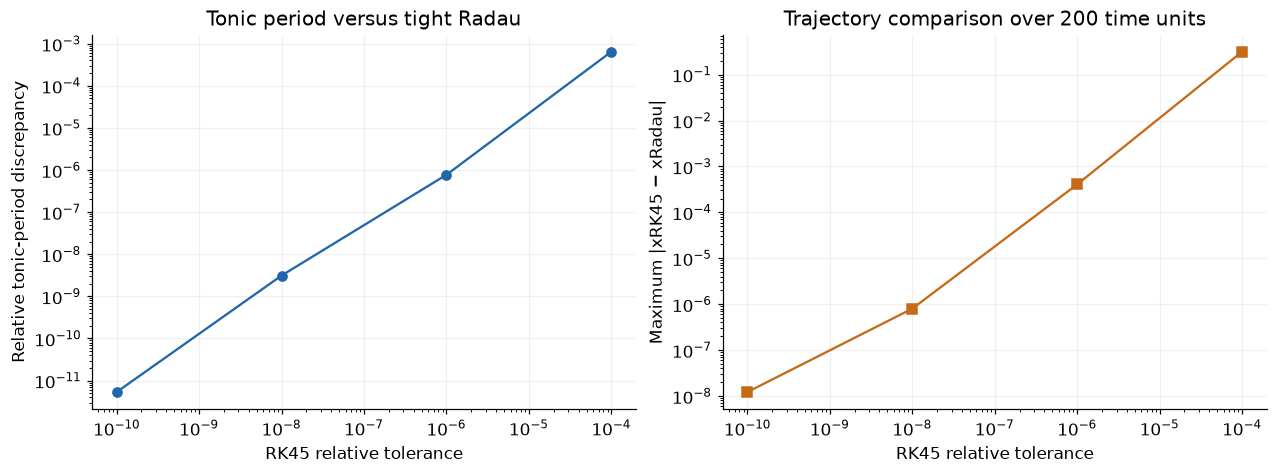

In [20]:
tonic_initial = solutions[4.].y_events[0][-1].copy()
tonic_initial[0] = 0.

def tonic_period(sol):
    events = sol.t_events[0]
    events = events[events > 1e-7]
    if len(events) < 6:
        raise RuntimeError('Too few tonic events for a last-5-ISI estimate.')
    return float(np.diff(events[-6:]).mean())

tonic_reference = integrate(4., tonic_initial, 400., method='Radau',
                             rtol=1e-11, atol=1e-13, max_step=0.1)
tonic_dop = integrate(4., tonic_initial, 400., rtol=1e-11, atol=1e-13, max_step=0.1)
T_TONIC = tonic_period(tonic_reference)
tonic_method_error = abs(tonic_period(tonic_dop)/T_TONIC-1)
tonic_closure = float(np.linalg.norm(tonic_reference.y_events[0][-1]-tonic_reference.y_events[0][-2]))
comparison_times = np.linspace(0, 200, 5001)
ref_x = tonic_reference.sol(comparison_times)[0]
convergence_rows = []
for tolerance in [1e-4, 1e-6, 1e-8, 1e-10]:
    sol = integrate(4., tonic_initial, 400., method='RK45', rtol=tolerance,
                    atol=tolerance/100, max_step=1.)
    convergence_rows.append({'rtol': tolerance, 'tonic_period': tonic_period(sol),
                             'relative_period_error': abs(tonic_period(sol)/T_TONIC-1),
                             'max_x_trajectory_error': float(np.max(abs(sol.sol(comparison_times)[0]-ref_x))),
                             'nfev': sol.nfev})
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR/'solver_convergence.csv', index=False)
display(convergence_table)

regular_groups = complete_groups(solutions[2.].t_events[0], BURN, STOP)
burst_initial = solutions[2.].sol(float(regular_groups.group_onset.iloc[-2]))
burst_initial[0] = 0.
burst_reference = integrate(2., burst_initial, 650., method='Radau',
                             rtol=1e-11, atol=1e-13, max_step=0.1)
burst_dop = integrate(2., burst_initial, 650., rtol=1e-11, atol=1e-13, max_step=0.1)
burst_groups_ref = complete_groups(burst_reference.t_events[0], 1e-7, 650.)
burst_groups_dop = complete_groups(burst_dop.t_events[0], 1e-7, 650.)
if min(len(burst_groups_ref), len(burst_groups_dop)) < 3:
    raise RuntimeError('Too few complete groups for period benchmark.')
T_BURST = float(np.diff(burst_groups_ref.group_onset).mean())
T_BURST_DOP = float(np.diff(burst_groups_dop.group_onset).mean())
burst_method_error = abs(T_BURST_DOP/T_BURST-1)
burst_onsets = burst_groups_ref.group_onset.to_numpy(dtype=float)
burst_closure = float(np.max(np.linalg.norm(np.diff(burst_reference.sol(burst_onsets), axis=1), axis=0)))
print(f'Tonic numerical reference period: {T_TONIC:.9f}')
print(f'Two-spike-group numerical reference period: {T_BURST:.9f}')
print(f'Radau/DOP853 relative differences: tonic {tonic_method_error:.3e}, group {burst_method_error:.3e}')
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), layout='constrained')
axes[0].loglog(convergence_table.rtol, convergence_table.relative_period_error, 'o-', color=COLORS['x'])
axes[0].set(xlabel='RK45 relative tolerance', ylabel='Relative tonic-period discrepancy',
            title='Tonic period versus tight Radau')
axes[1].loglog(convergence_table.rtol, convergence_table.max_x_trajectory_error, 's-', color=COLORS['z'])
axes[1].set(xlabel='RK45 relative tolerance', ylabel='Maximum |xRK45 − xRadau|',
            title='Trajectory comparison over 200 time units')
show_and_save(fig, '08_solver_convergence')

## Checks
### Algebra, independent implementations, and numerical reference checks
The slow equation is linear in $z$ when the computed $x(t)$ is treated as input. Its integrating-factor identity is
$$z(T)=z(0)e^{-rT}+rs\int_0^T e^{-r(T-u)}[x(u)-x_R]du.$$
A short, tightly integrated trajectory is independently quadrature-checked against this identity. Setting $r=0$ freezes $z$ and should reproduce the separate two-dimensional fast ODE. These checks complement, rather than replace, derivative checks and regular-orbit convergence.

Declared tolerances below concern these experiments. They do not bound long-time pointwise error of the irregular case or establish biological accuracy. Synthetic event-schedule assertions above test measurement logic only.

In [21]:
eq_residual = 0.
root_error = 0.
jac_error = 0.
h = 1e-5
for current in [0., 1.3, 2., 3.25, 4.]:
    point = equilibrium(current)
    eq_residual = max(eq_residual, float(np.linalg.norm(hr_rhs(0, point, current))))
    roots = np.roots([A, D-B, S, -(C+S*X_REF+current)])
    real_roots = roots[np.abs(roots.imag) < 1e-10].real
    assert len(real_roots) == 1
    root_error = max(root_error, abs(real_roots[0]-point[0]))
    numerical_j = np.column_stack([(hr_rhs(0, point+h*axis, current)
                                    -hr_rhs(0, point-h*axis, current))/(2*h)
                                   for axis in np.eye(3)])
    jac_error = max(jac_error, float(np.max(abs(numerical_j-hr_jacobian(point)))))

short = integrate(2., INITIAL, 20., rtol=1e-11, atol=1e-13, max_step=0.05)
integral, integral_error_estimate = quad(
    lambda u: np.exp(-R*(20-u))*(short.sol(u)[0]-X_REF), 0, 20,
    points=short.t[1:-1], limit=2000, epsabs=1e-10, epsrel=1e-10)
slow_identity_z = INITIAL[2]*np.exp(-R*20)+R*S*integral
slow_identity_error = abs(slow_identity_z-short.y[2, -1])
frozen_initial = np.array([1., 0., 2.])
frozen_full = integrate(2., frozen_initial, 30., slow_rate=0., rtol=1e-11, atol=1e-13, max_step=0.05)
frozen_fast = integrate_fast(2., 2., frozen_initial[:2], 30., rtol=1e-11, atol=1e-13, max_step=0.05)
check_times = np.linspace(0, 30, 1001)
frozen_error = float(np.max(abs(frozen_full.sol(check_times)[:2]-frozen_fast.sol(check_times))))
frozen_z_error = float(np.max(abs(frozen_full.sol(check_times)[2]-2)))
rest_error = float(np.linalg.norm(solutions[0.].y[:, -1]-equilibrium(0.)))
checks = [
    ('Full equilibrium residual', eq_residual, 1e-10),
    ('Independent polynomial root agreement', root_error, 1e-10),
    ('Analytic versus finite-difference Jacobian', jac_error, 1e-7),
    ('Slow-variable integrating-factor identity', slow_identity_error, 1e-8),
    ('Frozen full versus independent fast trajectory', frozen_error, 1e-7),
    ('Exact frozen-z constancy when r=0', frozen_z_error, 1e-12),
    ('Rest endpoint distance', rest_error, 1e-8),
    ('Tonic section-state closure', tonic_closure, 1e-6),
    ('Regular-group onset section closure', burst_closure, 1e-6),
    ('Radau/DOP853 relative tonic period', tonic_method_error, 1e-7),
    ('Radau/DOP853 relative group period', burst_method_error, 1e-7),
    ('Tight RK45 relative tonic period', convergence_table.relative_period_error.iloc[-1], 1e-6),
    ('Tight RK45 x trajectory discrepancy', convergence_table.max_x_trajectory_error.iloc[-1], 1e-4)]
check_table = pd.DataFrame(checks, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert regime_table.loc[regime_table.I == 0, 'spikes_in_window'].iloc[0] == 0
assert len(regular_groups) > 10 and np.all(regular_groups.n_spikes == 2)
assert np.all(burst_groups_ref.n_spikes == 2) and np.all(burst_groups_dop.n_spikes == 2)
for gap in [30., 50., 80.]:
    gg = complete_groups(solutions[2.].t_events[0], BURN, STOP, gap)
    assert len(gg) > 10 and np.all(gg.n_spikes == 2)
assert convergence_table.relative_period_error.iloc[-1] < convergence_table.relative_period_error.iloc[0]
assert np.all(regular_groups.preceding_isi > GAP) and np.all(regular_groups.following_isi > GAP)
check_table.to_csv(OUTPUT_DIR/'validation_checks.csv', index=False)
display(check_table)
print('All tabulated numerical criteria and measurement/protocol assertions passed.')

,check,observed_error,limit,passed
0,Full equilibrium residual,2.1538327e-14,1.0000000e-10,True
1,Independent polynomial root agreement,5.5511151e-15,1.0000000e-10,True
2,Analytic versus finite-difference Jacobian,2.3167601e-10,1.0000000e-07,True
3,Slow-variable integrating-factor identity,0.0000000e+00,1.0000000e-08,True
4,Frozen full versus independent fast trajectory,8.9519947e-11,1.0000000e-07,True
5,Exact frozen-z constancy when r=0,0.0000000e+00,1.0000000e-12,True
6,Rest endpoint distance,7.1213642e-10,1.0000000e-08,True
7,Tonic section-state closure,1.7120116e-13,1.0000000e-06,True
8,Regular-group onset section closure,2.1220075e-12,1.0000000e-06,True
9,Radau/DOP853 relative tonic period,1.1122214e-12,1.0000000e-07,True


All tabulated numerical criteria and measurement/protocol assertions passed.


## Takeaways
The following quantitative summary is generated from executed results. The irregular example remains descriptive: this notebook does not integrate variational equations, estimate Lyapunov exponents, or prove chaos. The high ISI CV of the regular two-spike burst is a direct counterexample to treating CV alone as a chaos test.

In [24]:
regular_stats = regime_table[regime_table.I == 2.].iloc[0]
tonic_stats = regime_table[regime_table.I == 4.].iloc[0]
summary = {
    'versions': VERSIONS, 'units': 'dimensionless',
    'parameters': {'a': A, 'b': B, 'c': C, 'd': D, 's': S, 'x_R': X_REF, 'r': R},
    'initial_condition': INITIAL.tolist(), 'analysis_window': [BURN, STOP],
    'default_grouping_gap': GAP,
    'regular_example_I': 2., 'regular_group_size': 2,
    'regular_group_period_reference': T_BURST,
    'regular_example_isi_cv': float(regular_stats.isi_cv),
    'tonic_example_I': 4., 'tonic_period_reference': T_TONIC,
    'tonic_method_relative_difference': float(tonic_method_error),
    'group_method_relative_difference': float(burst_method_error),
    'irregular_example_I': 3.25,
    'chaos_diagnosis': 'not performed; descriptive irregularity only',
    'accuracy_checks_passed': int(check_table.passed.sum())}
(OUTPUT_DIR/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
display(Markdown(f"""
- **Rest:** no post-transient spikes at **I=0**; final equilibrium distance **{rest_error:.2e}**.
- **Regular two-spike groups:** at **I=2**, reference group-onset period **{T_BURST:.6f}** model-time units, robustly two spikes per complete group for gap thresholds **30, 50, 80**.
- **ISI variability is not chaos:** that regular burst has **ISI CV = {regular_stats.isi_cv:.6f}** because its short/long intervals alternate.
- **Tonic spiking:** at **I=4**, reference spike period **{T_TONIC:.6f}** model-time units.
- **Cross-method agreement:** Radau/DOP853 relative period differences are **{tonic_method_error:.2e}** (tonic) and **{burst_method_error:.2e}** (regular group). Neither is an error bound against an exact nonlinear period.
- **Irregular example:** at **I=3.25**, temporal grouping depends materially on the gap threshold. The waveform and return map do not establish chaos.
- **Verification:** all **{len(check_table)}** tabulated numerical criteria and additional event/grouping assertions passed.
"""))


- **Rest:** no post-transient spikes at **I=0**; final equilibrium distance **7.12e-10**.
- **Regular two-spike groups:** at **I=2**, reference group-onset period **128.504845** model-time units, robustly two spikes per complete group for gap thresholds **30, 50, 80**.
- **ISI variability is not chaos:** that regular burst has **ISI CV = 0.779285** because its short/long intervals alternate.
- **Tonic spiking:** at **I=4**, reference spike period **20.127868** model-time units.
- **Cross-method agreement:** Radau/DOP853 relative period differences are **1.11e-12** (tonic) and **2.84e-12** (regular group). Neither is an error bound against an exact nonlinear period.
- **Irregular example:** at **I=3.25**, temporal grouping depends materially on the gap threshold. The waveform and return map do not establish chaos.
- **Verification:** all **13** tabulated numerical criteria and additional event/grouping assertions passed.


## Next steps
The project now has a single-node mathematical spine: theta/QIF → Hopf normal forms → FHN recovery dynamics → HR slow adaptation/bursting.

**Proposed next step:** a model-independent simulation/measurement interface, followed by **two coupled identical neurons** with an explicit coupling convention. Start with a single model and calibrated mathematical input/output channels before graph comparisons or mixed-model nodes. Test zero-coupling recovery of independent trajectories, symmetry of identical initial conditions, sign/strength of the chosen coupling, and convergence. Diffusive activation coupling is a mathematical baseline; biological electrical/chemical interpretation requires further scaling and synaptic assumptions.

A separate HR follow-up could compute converged Lyapunov spectra, unstable cycles, or a detailed multi-parameter bifurcation diagram. Those are not replaced by the descriptive irregular example here and are not needed to label the verified regular baseline cases.

### References and provenance
- Hindmarsh & Rose (1984), *A model of neuronal bursting using three coupled first order differential equations*, Proc. R. Soc. B 221, 87–102. [Original abstract/record](https://pubmed.ncbi.nlm.nih.gov/6144106/), [DOI](https://doi.org/10.1098/rspb.1984.0024).
- Barrio & Shilnikov (2011), *Parameter-sweeping techniques for temporal dynamics of neuronal systems: case study of Hindmarsh–Rose model*, J. Mathematical Neuroscience 1:6. [Open full text](https://pmc.ncbi.nlm.nih.gov/articles/PMC3365907/), [DOI](https://doi.org/10.1186/2190-8567-1-6). Supports the equation family and the role of temporal metrics, slow–fast geometry, and independent Lyapunov analysis; its parameter cuts are not reproduced here.
- [SciPy solve_ivp documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), for numerical integration/event handling. Installed package versions appear in Setup. References consulted during preparation on 2026-10-26; supplied project PDFs are not analyzed.

**Limits:** one initial condition per current, finite burn-in/windows, and an operational event/grouping rule do not establish a complete attractor map. Frozen-fast cycle envelopes are selected trajectories, not exact bifurcation boundaries; the slow rate can invalidate naive quasistatic reasoning near fast bifurcations. No biological voltage/current/time calibration, universal burst threshold, refractory interval, or network collective behavior is inferred. The grouping gap must be reexamined when r changes; the exported slow-rate comparison remains conditional on the displayed gap rule. No chaos claim is made without a dedicated dynamical diagnostic and convergence study.